# Early Detection of Bovine Respiratory Disease
This notebook follows the full leakage-safe workflow: inspect the workbook, define the 1–6 day pre-diagnosis target, cluster the records (PCA + K-Means), split by calf, tune and train five tabular models (Logistic Regression, KNN, Random Forest, Gradient Boosting, MLP) and a 1D-CNN over 7-day histories, evaluate on unseen calves, and analyse failure cases.

In [1]:
from pathlib import Path
import sys
sys.path.append(str(Path.cwd().parent))
from src.data_preprocessing import *
from src.train import run_project
from src.utils import DATA_PATH

## 1. Load and inspect the dataset
The loader prints shape, columns, dtypes, missing values, duplicates, candidate identifiers, diagnosis fields, and descriptive statistics.

In [2]:
df, detected = load_dataset(DATA_PATH)

Dataset: /Users/rohitkunjam/Downloads/ML-mid project/data/Cantor_machineclean-opendepository.xlsx
Shape: (8706, 36)
Columns: ['Count', 'Observation', 'Date', 'Data_Points', 'Total_Steps', 'Total_MI', 'Lying_time', 'Lying_bouts', 'lying_daily', 'IdSeq', 'Gender', 'Season', 'Feederage', 'SENDER', 'Feederday', 'Enrolldate', 'Milk_Intake', 'Milk_percent', 'Speed', 'Speed_percent', 'Starter_Intake', 'Rewarded', 'Unrewarded', 'Herd', 'BIRTHDATE', 'BRIX', 'DPARITY', 'Pen', 'PERSON_SCORING', 'Fecal', 'Temp_score', 'Temp', 'Weight', 'Breath', 'Pneuday', 'agefeeder']
Dtypes:
 Count                    float64
Observation              float64
Date              datetime64[us]
Data_Points              float64
Total_Steps              float64
Total_MI                 float64
Lying_time                object
Lying_bouts              float64
lying_daily              float64
IdSeq                    float64
Gender                   float64
Season                   float64
Feederage                float6

## 2. Target construction and feature selection
Positive observations are `-6 <= Pneuday <= -1`. Controls are all observations from calves without a recorded diagnosis day (`Pneuday = 0`). Diagnosis fields, identifiers, dates, `Count` (running row number), `Observation` (record index), `agefeeder` (duplicate of `Feederage`) and the constant `Herd` are excluded. `Lying_time` is converted from HH:MM:SS to minutes and scorer-name spellings are merged.

In [3]:
modeled, target_info = create_target(df, detected['calf_id'], detected['pneuday'])
features, numeric, categorical, excluded = select_features(modeled, detected['calf_id'], detected['pneuday'])


Target construction: target=1 for -6 <= Pneuday <= -1; target=0 for calves without Pneuday=0.
Number of positive samples: 316
Number of negative samples: 4298
Number of positive calves: 54
Number of healthy calves: 57
Excluded leakage/identifier/date columns: ['IdSeq', 'SENDER', 'Pneuday', '_row', 'target', 'Count', 'Observation', 'Date', 'Enrolldate', 'Herd', 'BIRTHDATE', 'agefeeder']
Final features used (26): ['Data_Points', 'Total_Steps', 'Total_MI', 'Lying_time', 'Lying_bouts', 'lying_daily', 'Gender', 'Season', 'Feederage', 'Feederday', 'Milk_Intake', 'Milk_percent', 'Speed', 'Speed_percent', 'Starter_Intake', 'Rewarded', 'Unrewarded', 'BRIX', 'DPARITY', 'Pen', 'PERSON_SCORING', 'Fecal', 'Temp_score', 'Temp', 'Weight', 'Breath']
Numeric features: ['Data_Points', 'Total_Steps', 'Total_MI', 'Lying_time', 'Lying_bouts', 'lying_daily', 'Gender', 'Season', 'Feederage', 'Feederday', 'Milk_Intake', 'Milk_percent', 'Speed', 'Speed_percent', 'Starter_Intake', 'Rewarded', 'Unrewarded', 'BR

## 3. Exploratory analysis and leakage discussion
Repeated daily observations mean row-level random splitting could place the same calf in both partitions. The project therefore uses calf ID as the grouping variable everywhere (test split, grid search, threshold tuning, cross-validation).

In [4]:
display(modeled[features].head())
display(modeled['target'].value_counts())
display(modeled[numeric].describe().T.round(2))

,Data_Points,Total_Steps,Total_MI,Lying_time,Lying_bouts,lying_daily,Gender,Season,Feederage,Feederday,...,Unrewarded,BRIX,DPARITY,Pen,PERSON_SCORING,Fecal,Temp_score,Temp,Weight,Breath
0,96.0,353.0,1788.0,1152.266667,27.0,19.0,0.0,4.0,3.0,21.0,...,6.0,0.089,6.0,4.0,Melissa,2.0,0.0,38.3,NaN,0.0
1,96.0,975.0,5684.0,1050.533333,37.0,17.0,0.0,4.0,3.0,22.0,...,6.0,0.089,6.0,4.0,Melissa,2.0,0.0,37.3,NaN,0.0
2,96.0,522.0,2431.0,844.216667,19.0,14.0,0.0,4.0,3.0,23.0,...,2.0,0.089,6.0,4.0,Melissa,2.0,1.0,38.6,55.4,0.0
3,96.0,416.0,2170.0,961.033333,14.0,16.0,0.0,4.0,3.0,24.0,...,1.0,0.089,6.0,4.0,Megan,1.0,3.0,39.6,NaN,0.0
4,96.0,193.0,946.0,1055.566667,15.0,17.0,0.0,4.0,3.0,25.0,...,6.0,0.089,6.0,4.0,Melissa,2.0,2.0,39.0,NaN,0.0


target
0    4298
1     316
Name: count, dtype: int64

,count,mean,std,min,25%,50%,75%,max
Data_Points,4613.0,95.74,4.50,28.00,96.00,96.00,96.00,192.00
Total_Steps,4613.0,522.58,343.72,0.00,270.00,476.00,712.00,3376.00
Total_MI,4613.0,2774.68,1715.71,5.00,1486.00,2507.00,3743.00,14169.00
Lying_time,4612.0,1056.65,127.24,93.23,999.92,1062.07,1126.62,1439.98
Lying_bouts,4613.0,19.07,6.25,1.00,15.00,19.00,23.00,46.00
lying_daily,4613.0,17.10,2.13,1.00,16.00,17.00,18.00,23.00
Gender,4614.0,0.70,0.46,0.00,0.00,1.00,1.00,1.00
Season,4614.0,2.61,1.05,1.00,2.00,3.00,3.00,4.00
Feederage,4614.0,3.03,1.43,1.00,2.00,3.00,4.00,8.00
Feederday,4614.0,39.58,23.52,1.00,20.00,37.00,59.75,86.00


## 4. Calf-level split
The `ColumnTransformer` (median imputation + scaling, one-hot encoding) is inside each model pipeline, so it is fitted only on training calves.

In [5]:
train, test = split_by_calf(modeled, detected['calf_id'])

Train calves: 85
Test calves: 22
Train samples: 3733
Test samples: 881
Calf overlap: set()
Train class distribution: {0: 3483, 1: 250}
Test class distribution: {0: 815, 1: 66}


## 5. Reproduce the complete experiment
Runs clustering, grouped grid-search + F2 threshold tuning for the tabular models, the 1D-CNN, test-set evaluation, grouped cross-validation, learning/loss curves and the failure analysis. Takes about 3–4 minutes on a laptop CPU.

In [6]:
summary = run_project(DATA_PATH)

Dataset: /Users/rohitkunjam/Downloads/ML-mid project/data/Cantor_machineclean-opendepository.xlsx
Shape: (8706, 36)
Columns: ['Count', 'Observation', 'Date', 'Data_Points', 'Total_Steps', 'Total_MI', 'Lying_time', 'Lying_bouts', 'lying_daily', 'IdSeq', 'Gender', 'Season', 'Feederage', 'SENDER', 'Feederday', 'Enrolldate', 'Milk_Intake', 'Milk_percent', 'Speed', 'Speed_percent', 'Starter_Intake', 'Rewarded', 'Unrewarded', 'Herd', 'BIRTHDATE', 'BRIX', 'DPARITY', 'Pen', 'PERSON_SCORING', 'Fecal', 'Temp_score', 'Temp', 'Weight', 'Breath', 'Pneuday', 'agefeeder']
Dtypes:
 Count                    float64
Observation              float64
Date              datetime64[us]
Data_Points              float64
Total_Steps              float64
Total_MI                 float64
Lying_time                object
Lying_bouts              float64
lying_daily              float64
IdSeq                    float64
Gender                   float64
Season                   float64
Feederage                float6


CLUSTERING: PCA kept 16 components (91.8% variance); best k=2 (silhouette=0.162)
         records  pre_brd_rate
cluster                       
0           3314      0.095353
1           1300      0.000000
Train calves: 85
Test calves: 22
Train samples: 3733
Test samples: 881
Calf overlap: set()
Train class distribution: {0: 3483, 1: 250}
Test class distribution: {0: 815, 1: 66}


/Users/rohitkunjam/Downloads/ML-mid project/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/rohitkunjam/Downloads/ML-mid project/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/Users/rohitkunjam/Downloads/ML-mid project/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set

/Users/rohitkunjam/Downloads/ML-mid project/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/rohitkunjam/Downloads/ML-mid project/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/Users/rohitkunjam/Downloads/ML-mid project/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set

/Users/rohitkunjam/Downloads/ML-mid project/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


/Users/rohitkunjam/Downloads/ML-mid project/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/rohitkunjam/Downloads/ML-mid project/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  war

... (14 outputs left out)

/Users/rohitkunjam/Downloads/ML-mid project/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/rohitkunjam/Downloads/ML-mid project/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  war

/Users/rohitkunjam/Downloads/ML-mid project/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(



FAILURE ANALYSIS (Random Forest): {'TP': 54, 'FN': 12, 'FP': 294, 'TN': 521} | sick calves never flagged: 0/11 | healthy calves with a false alarm: 11/11



BRD MACHINE LEARNING PROJECT
Rows: 8706 | Calves: 107 | Positive calves: 54 | Healthy calves: 57
Train calves: 85 | Test calves: 22

TEST-SET RESULTS (tuned threshold)
----------------------------------------
              Model  Threshold  Accuracy  Precision  Recall    F1  ROC-AUC  Recall@0.5  F1@0.5
      Random Forest      0.448     0.653      0.155   0.818 0.261    0.781       0.697   0.267
  Gradient Boosting      0.078     0.667      0.137   0.652 0.227    0.702       0.000   0.000
                MLP      0.017     0.656      0.126   0.606 0.209    0.698       0.045   0.073
                KNN      0.060     0.572      0.114   0.697 0.196    0.636       0.000   0.000
Logistic Regression      0.266     0.379      0.105   0.970 0.190    0.685       0.591   0.181
             1D-CNN      0.407     0.607      0.111   0.606 0.188    0.694       0.576   0.208
----------------------------------------
Selected model (best training-CV average precision): Random Forest, threshold 0.448


## 6. Results
The final model is chosen by training-CV average precision, never by the test set. Thresholds are tuned for F2 (recall weighted twice as much as precision).

,Model,CV average precision,Best params,Tuned threshold,OOF precision,OOF recall,OOF f2
0,Random Forest,0.272500,"{""max_depth"": 4, ""min_samples_leaf"": 20}",0.448434,0.138399,0.816,0.412288
1,Gradient Boosting,0.186070,"{""learning_rate"": 0.05, ""max_depth"": 2, ""n_est...",0.078470,0.121507,0.748,0.368255
2,1D-CNN,0.144283,"{""window_days"": 7, ""epochs"": 3, ""conv_channels...",0.406711,NaN,NaN,NaN
3,Logistic Regression,0.141706,"{""C"": 0.01, ""penalty"": ""l2""}",0.266010,0.093688,0.944,0.335323
4,MLP,0.141244,"{""alpha"": 0.001, ""hidden_layer_sizes"": [64, 32...",0.016994,0.100723,0.780,0.332084
5,KNN,0.127374,"{""n_neighbors"": 51, ""weights"": ""distance""}",0.059535,0.109283,0.744,0.344189


,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,Recall@0.5,F1@0.5
0,Random Forest,0.448,0.653,0.155,0.818,0.261,0.781,0.697,0.267
1,Gradient Boosting,0.078,0.667,0.137,0.652,0.227,0.702,0.000,0.000
2,MLP,0.017,0.656,0.126,0.606,0.209,0.698,0.045,0.073
3,KNN,0.060,0.572,0.114,0.697,0.196,0.636,0.000,0.000
4,Logistic Regression,0.266,0.379,0.105,0.970,0.190,0.685,0.591,0.181
5,1D-CNN,0.407,0.607,0.111,0.606,0.188,0.694,0.576,0.208


,Model,Accuracy mean,Accuracy std,Precision mean,Precision std,Recall mean,Recall std,F1 mean,F1 std,ROC-AUC mean,ROC-AUC std
0,Logistic Regression,0.379,0.027,0.097,0.007,0.968,0.028,0.176,0.012,0.714,0.070
1,KNN,0.560,0.061,0.106,0.017,0.715,0.028,0.185,0.025,0.673,0.041
2,Random Forest,0.603,0.015,0.132,0.014,0.865,0.100,0.229,0.024,0.794,0.031
3,Gradient Boosting,0.639,0.058,0.133,0.034,0.751,0.122,0.226,0.054,0.744,0.076
4,MLP,0.535,0.105,0.104,0.009,0.746,0.164,0.181,0.013,0.700,0.067
5,1D-CNN,0.597,0.032,0.122,0.016,0.788,0.099,0.212,0.027,0.721,0.077


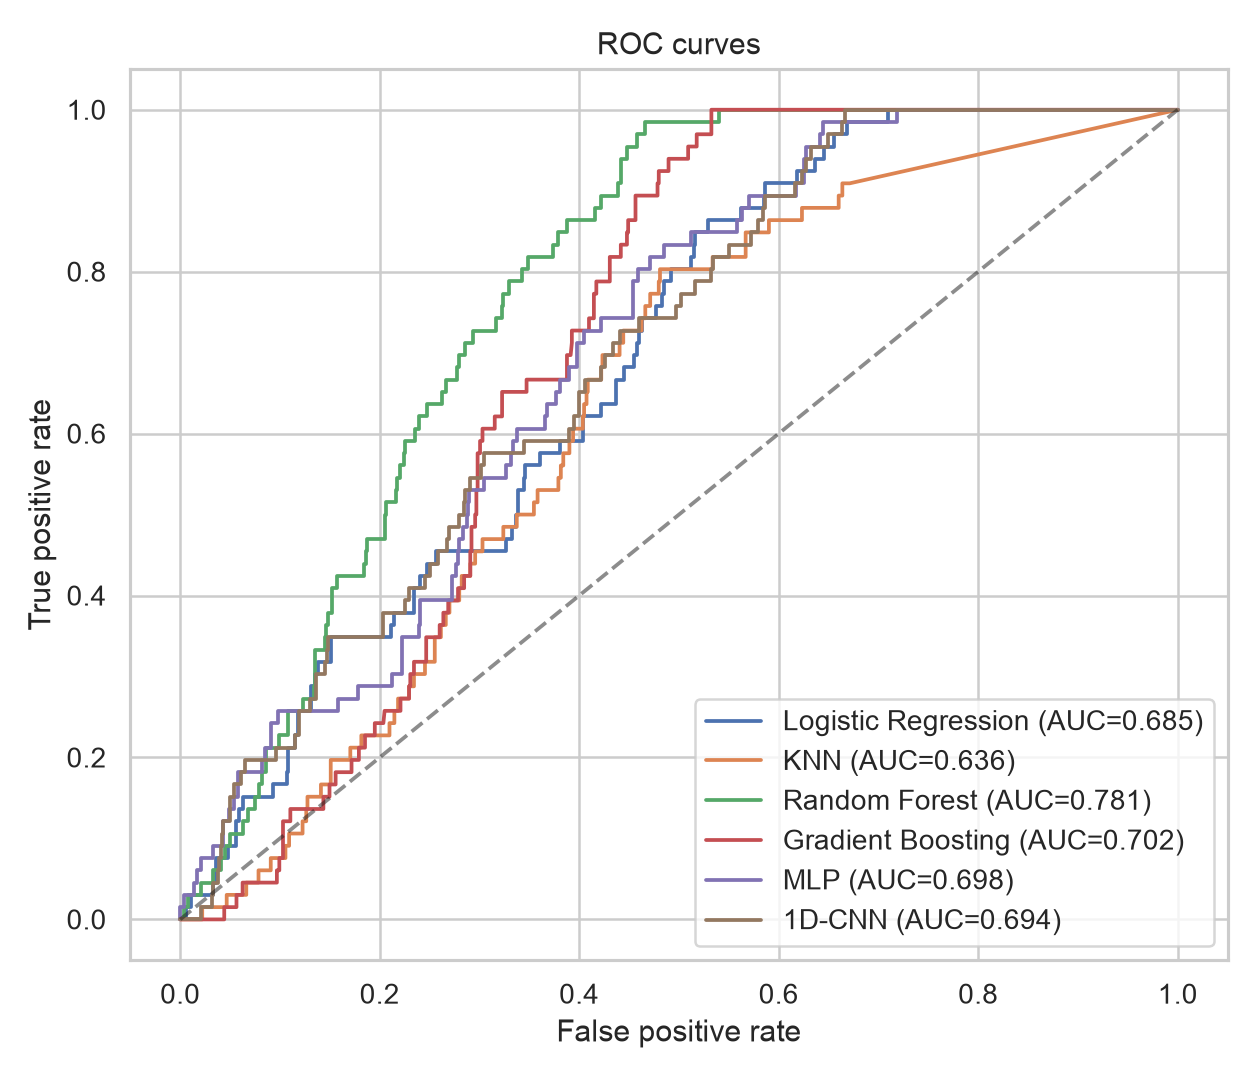

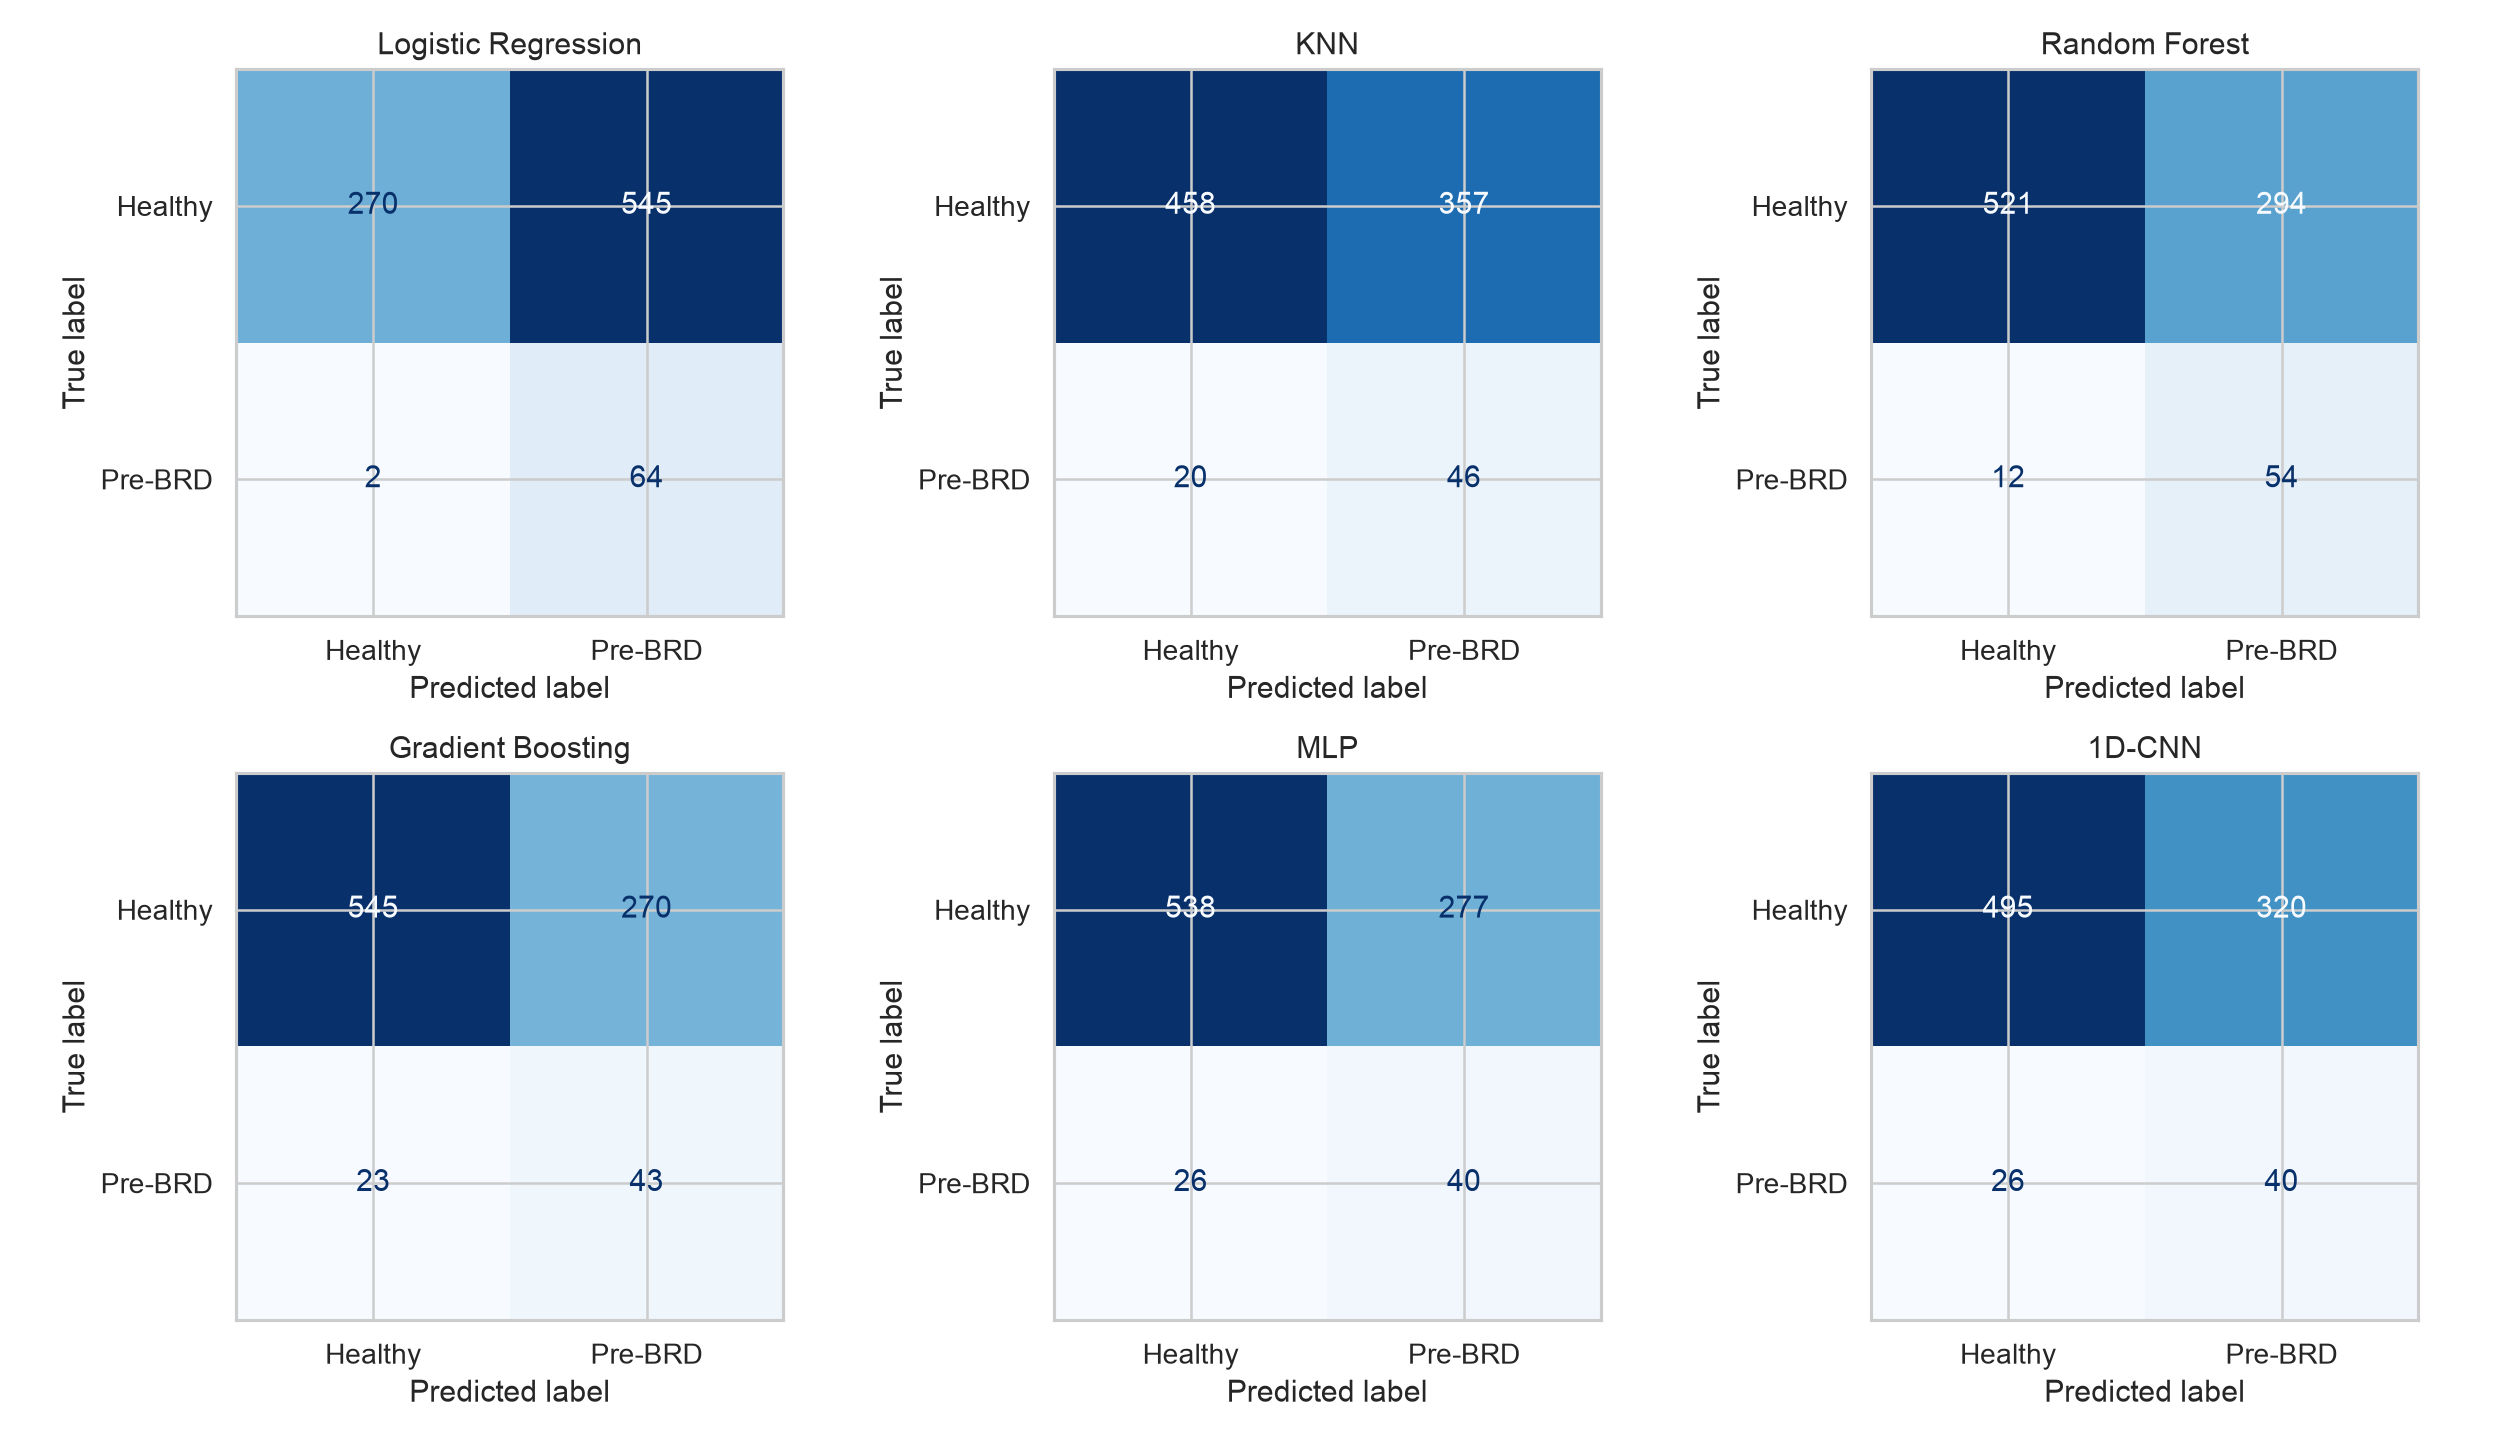

In [7]:
import pandas as pd, json
from IPython.display import Image
R='../outputs/results/'; F='../outputs/figures/'
display(pd.read_csv(R+'hyperparameter_tuning.csv'))
display(pd.read_csv(R+'model_results.csv').round(3))
display(pd.read_csv(R+'group_cross_validation.csv').round(3))
display(Image(F+'roc_curves.png', width=600)); display(Image(F+'confusion_matrices.png', width=800))

## 7. Unsupervised analysis (PCA + K-Means)

,k,inertia,silhouette
0,2,92171.833,0.162
1,3,83237.875,0.125
2,4,77724.304,0.129
3,5,74428.315,0.128
4,6,71276.259,0.133
5,7,69644.813,0.113
6,8,66976.335,0.098


,cluster,records,pre_brd_rate,Milk_Intake,Speed,Lying_time,Total_Steps,Starter_Intake,Temp,Weight,Feederage
0,0,3314,0.1,8.08,915.51,1090.42,507.29,259.12,38.66,56.50,3.02
1,1,1300,0.0,1.80,554.27,970.61,561.56,3187.94,38.50,92.63,3.07


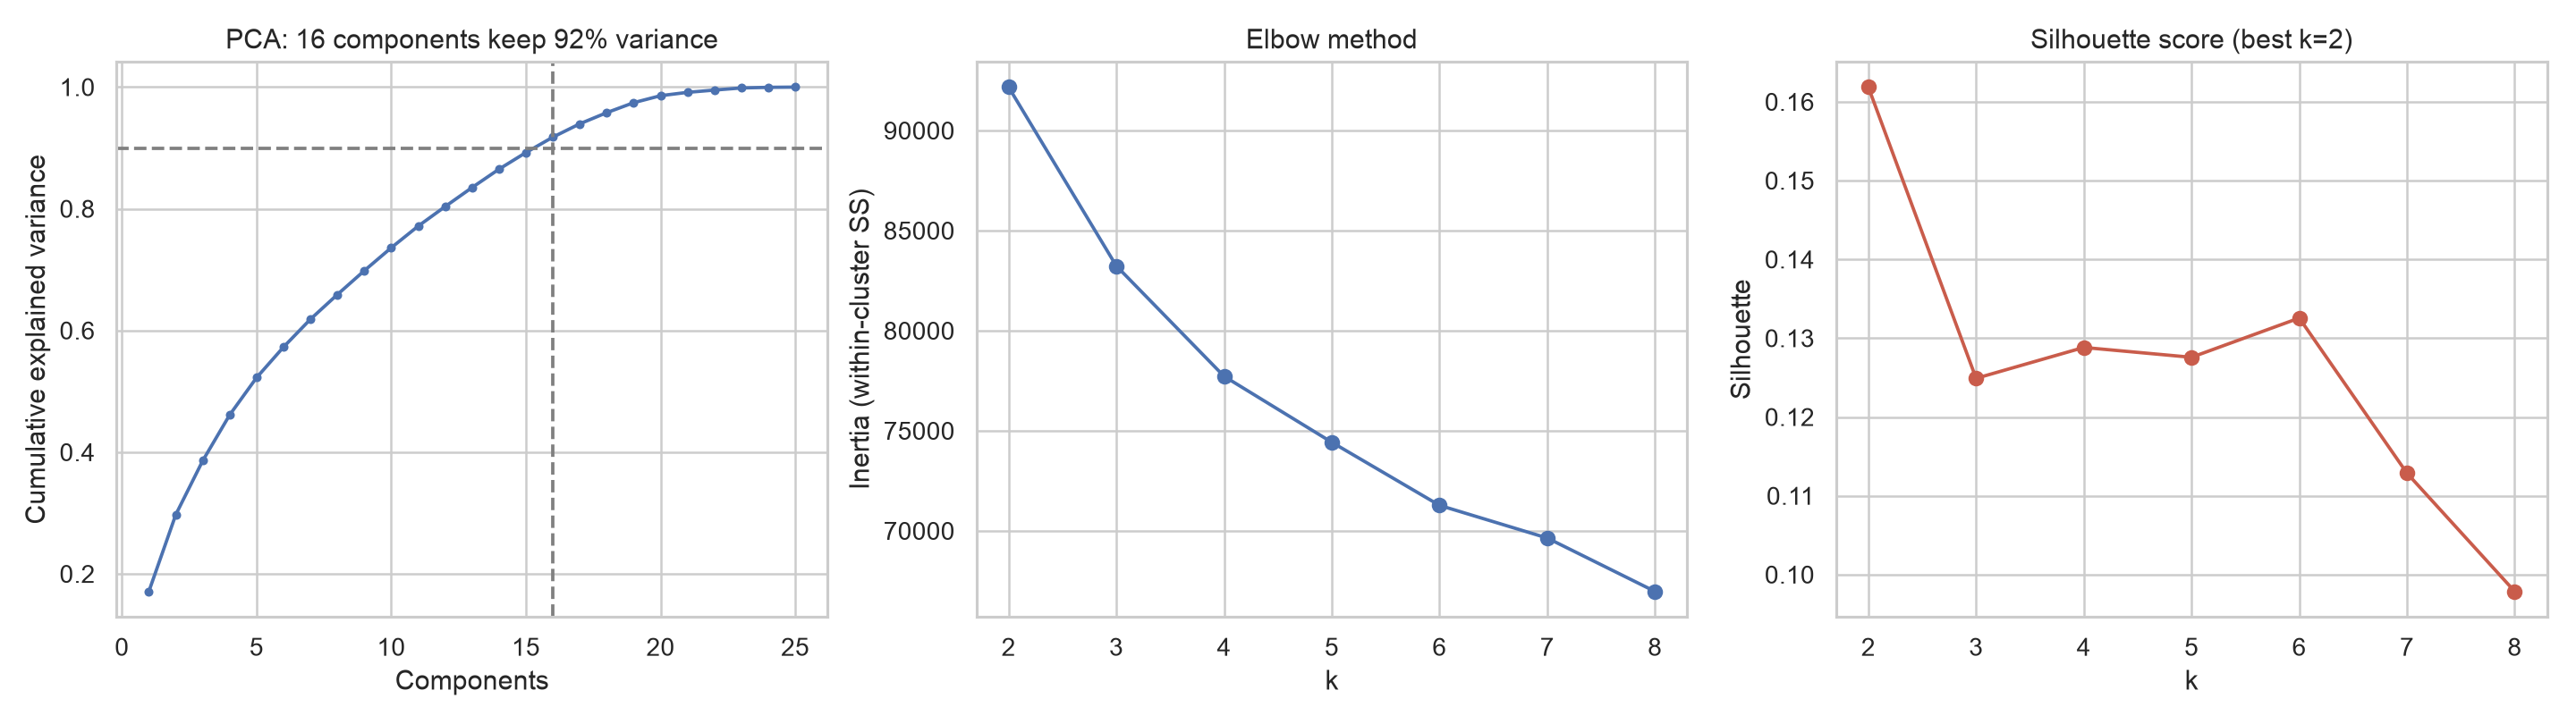

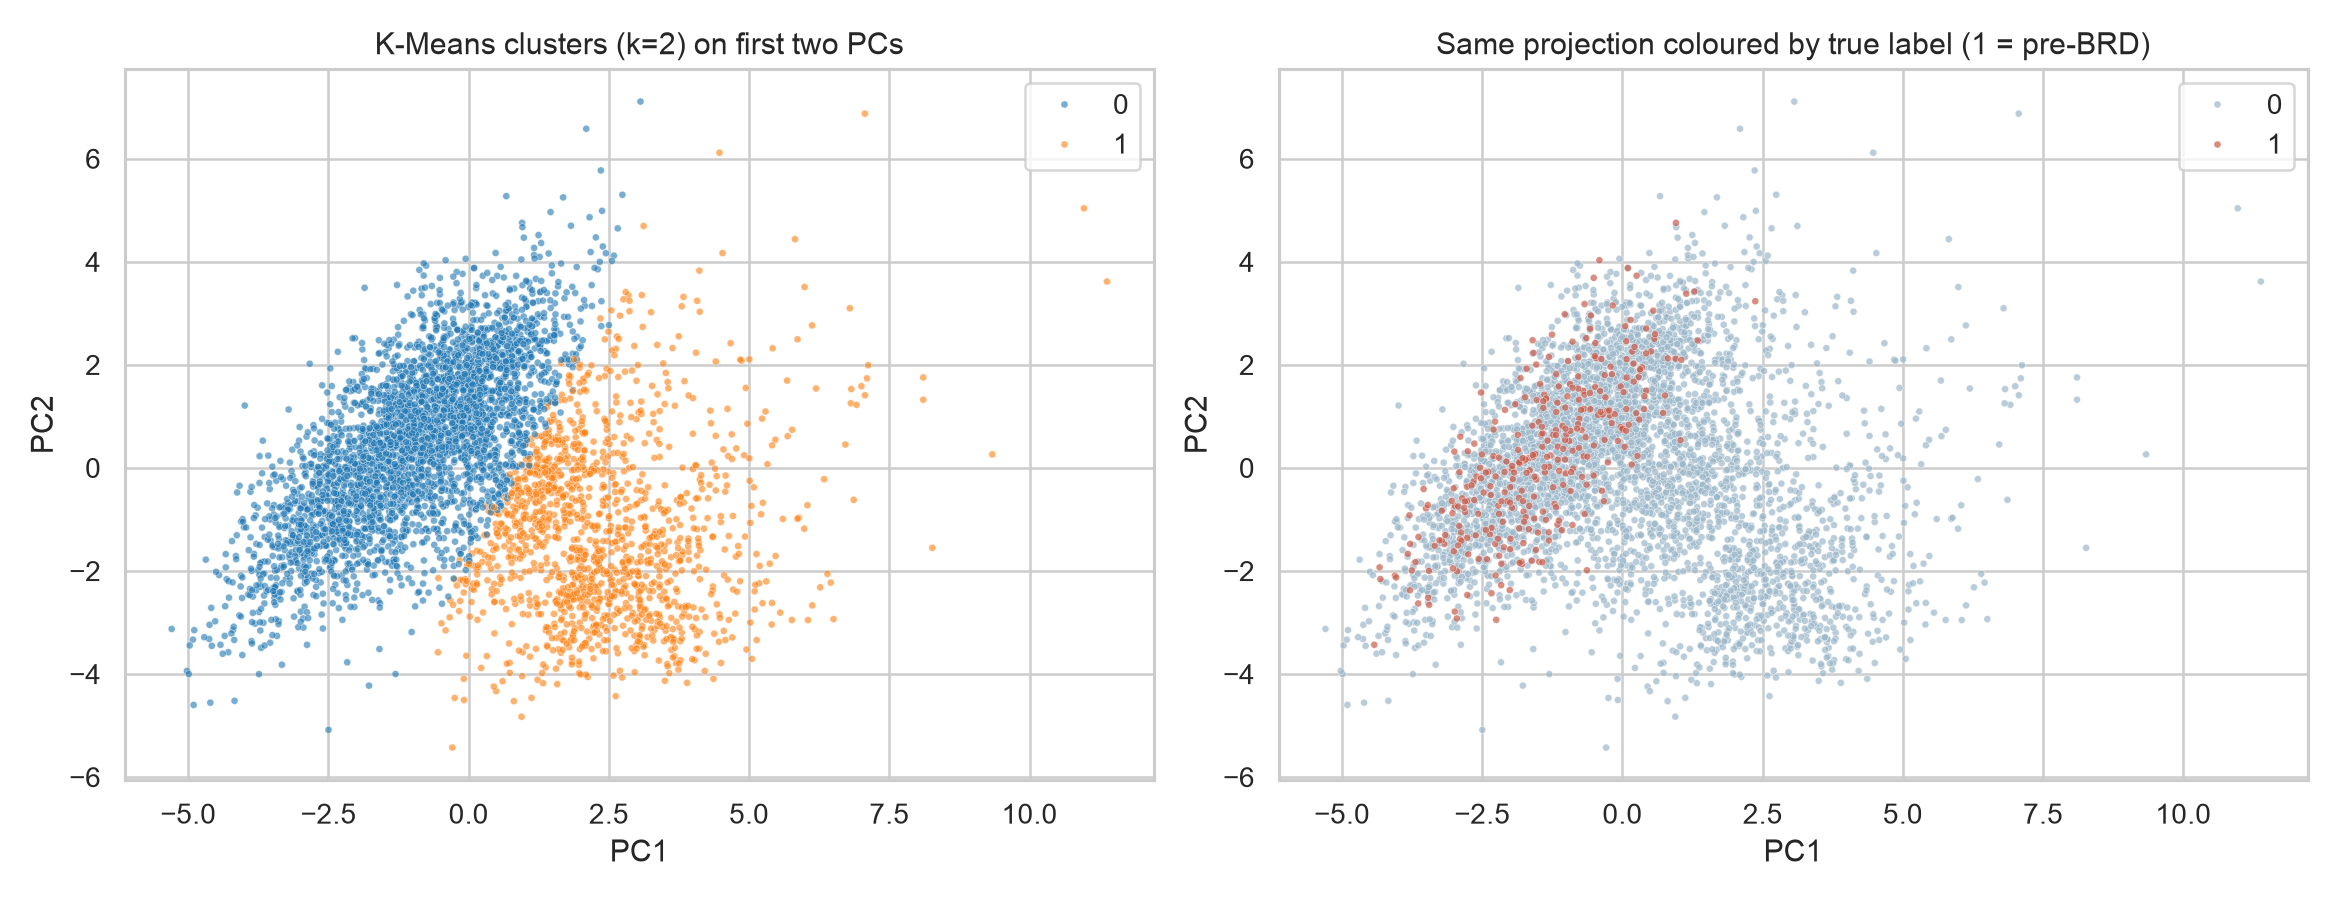

In [8]:
display(pd.read_csv(R+'clustering_scores.csv').round(3)); display(pd.read_csv(R+'cluster_profiles.csv').round(2))
display(Image(F+'clustering_selection.png', width=900)); display(Image(F+'clusters_pca.png', width=900))

## 8. Learning and loss curves

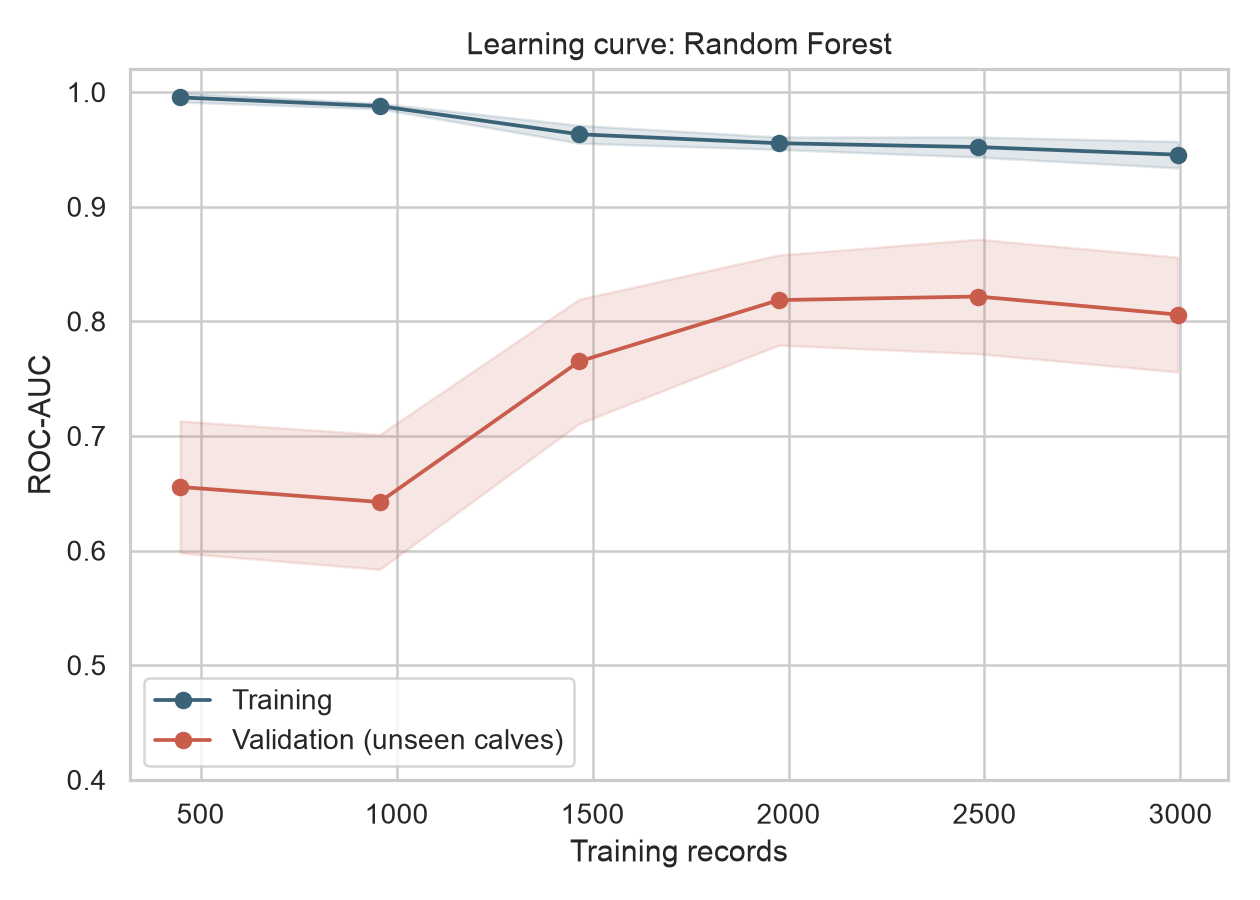

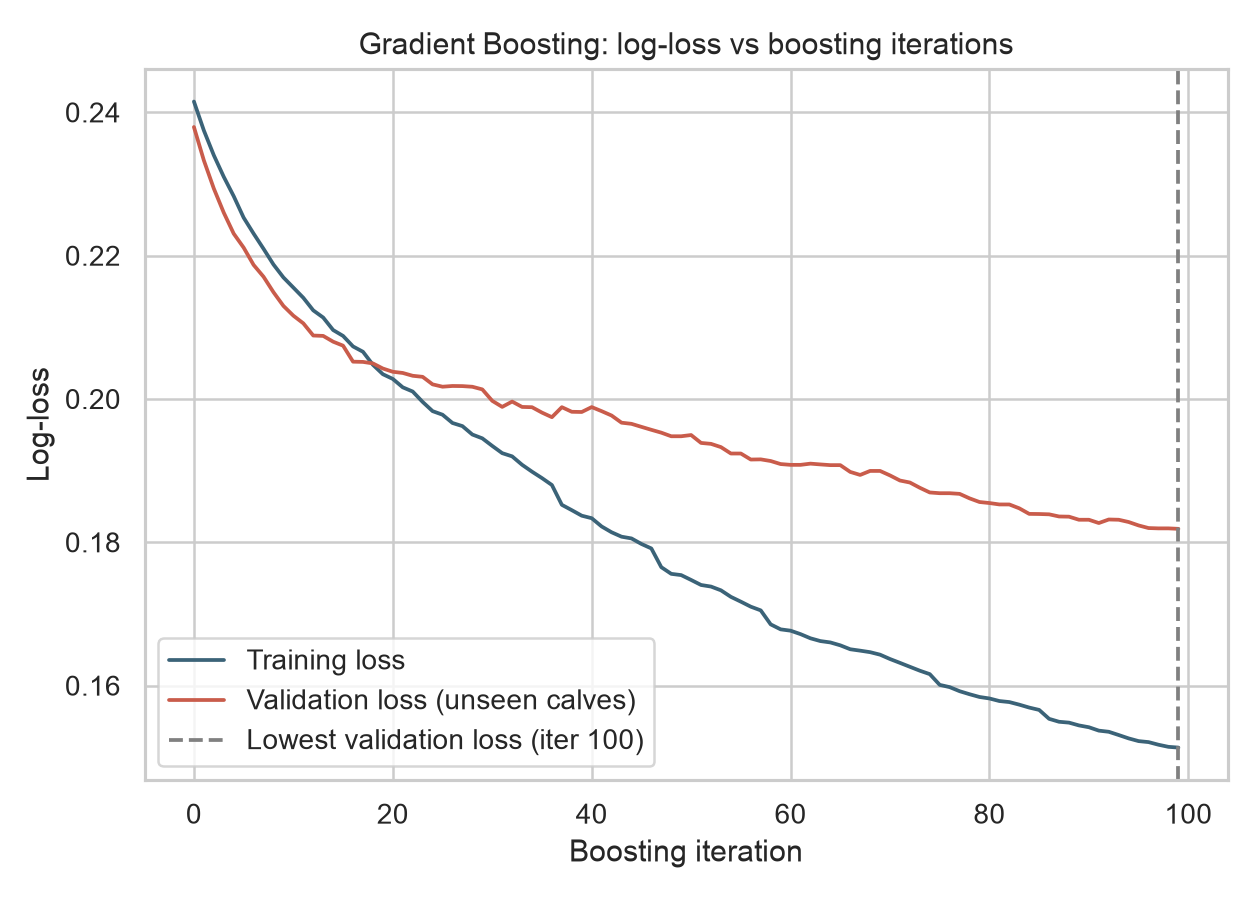

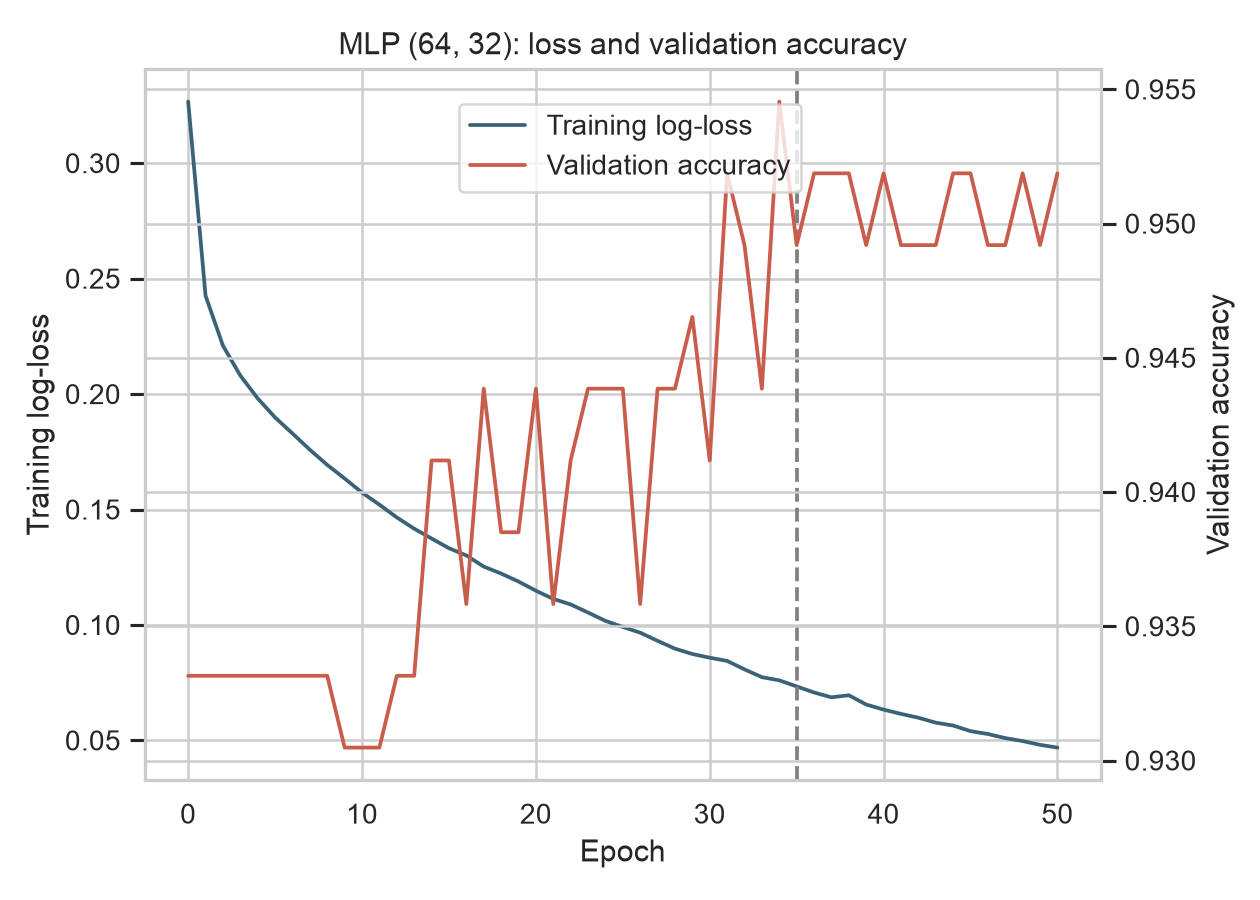

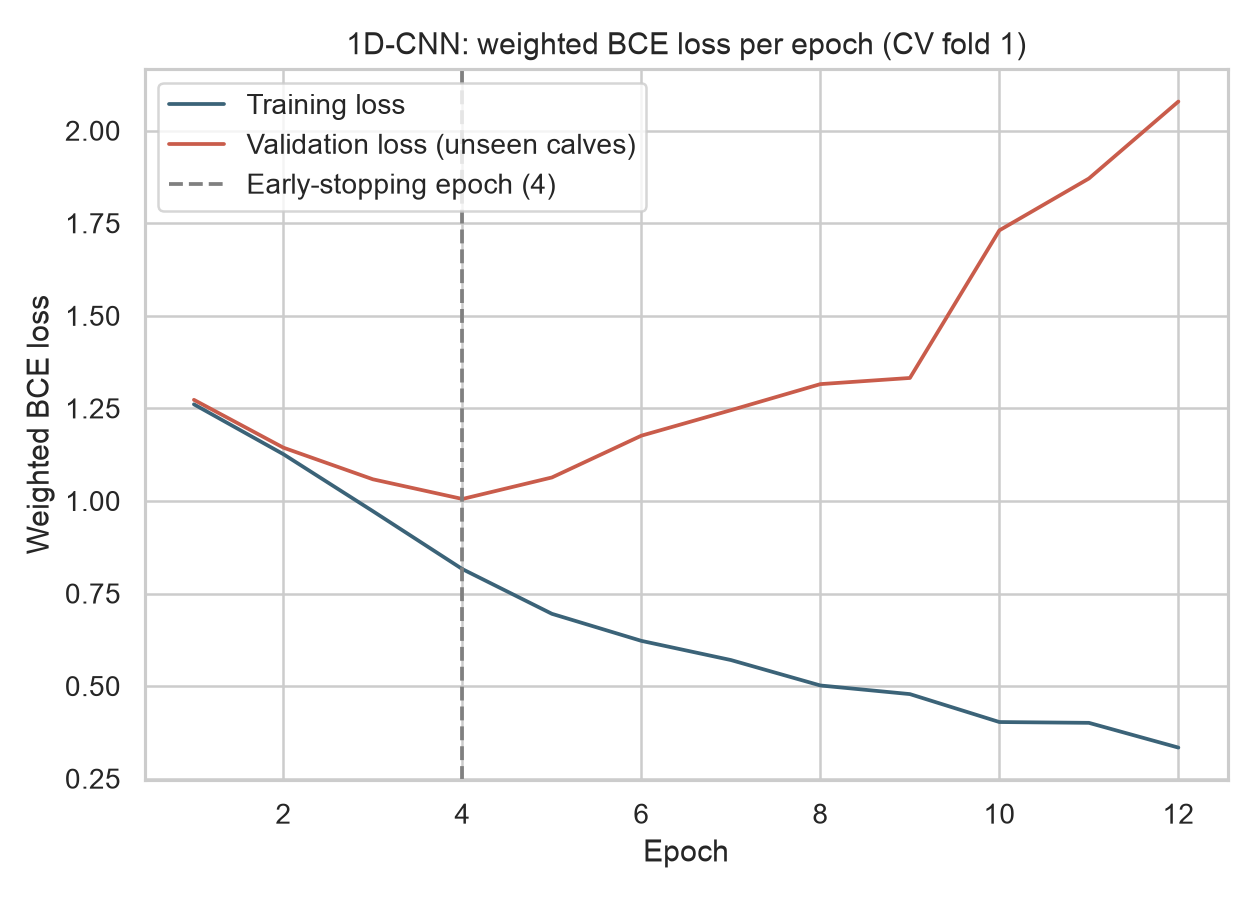

In [9]:
for f in ['learning_curve.png','boosting_loss_curve.png','mlp_loss_curve.png','cnn_loss_curve.png']: display(Image(F+f, width=550))

## 9. Failure-case analysis

{'confusion': {'TP': 54, 'FN': 12, 'FP': 294, 'TN': 521}, 'sick_calves_never_flagged': 0, 'healthy_calves_with_false_alarm': 11, 'age_matched_auc': {'Logistic Regression': 0.48148148148148145, 'KNN': 0.5217452300785634, 'Random Forest': 0.5868757014590348, 'Gradient Boosting': 0.4445145903479237, 'MLP': 0.4960718294051627, '1D-CNN': 0.49470398428731766}}


,age_band,healthy_records,false_alarm_rate,pre_brd_records,recall
0,1-14,147.0,0.646,12.0,0.667
1,15-28,145.0,0.834,20.0,1.000
2,29-42,140.0,0.557,34.0,0.765
3,43-56,140.0,0.000,0.0,NaN
4,57+,243.0,0.000,0.0,NaN


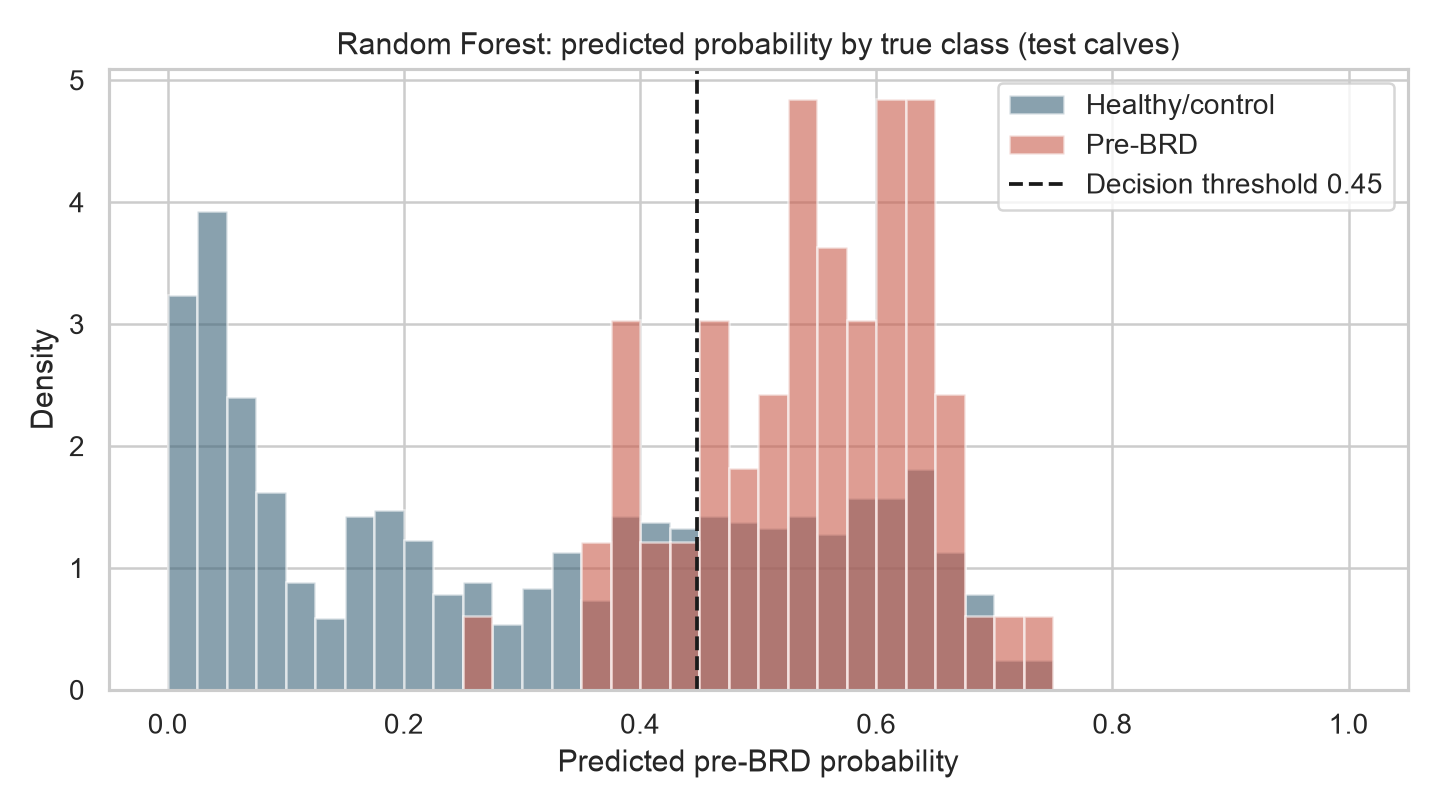

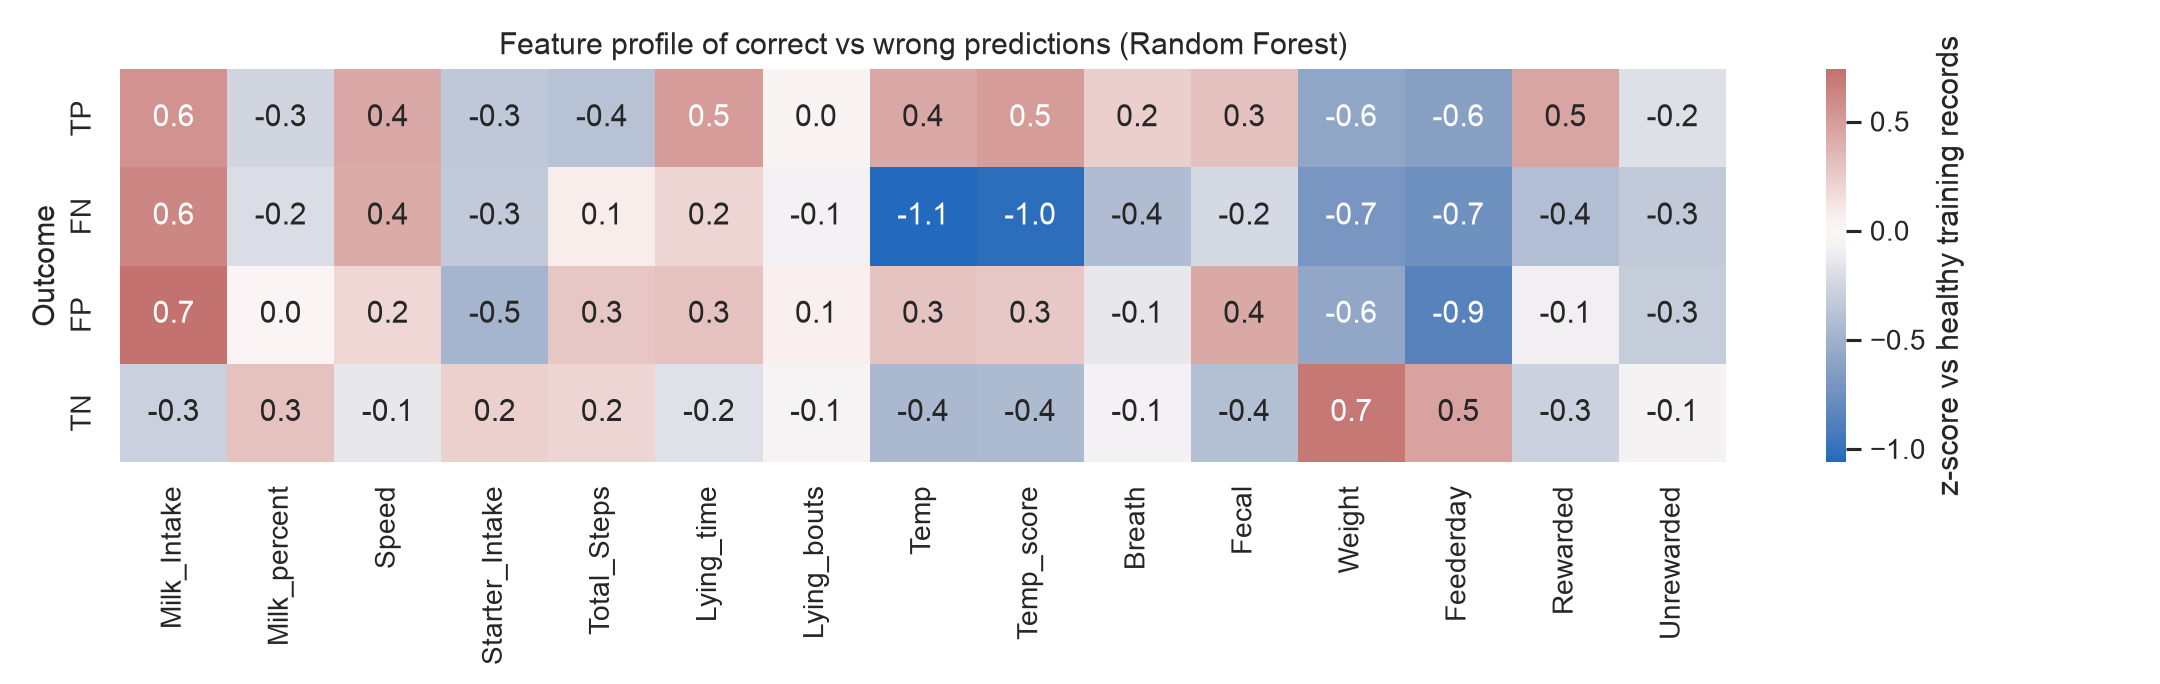

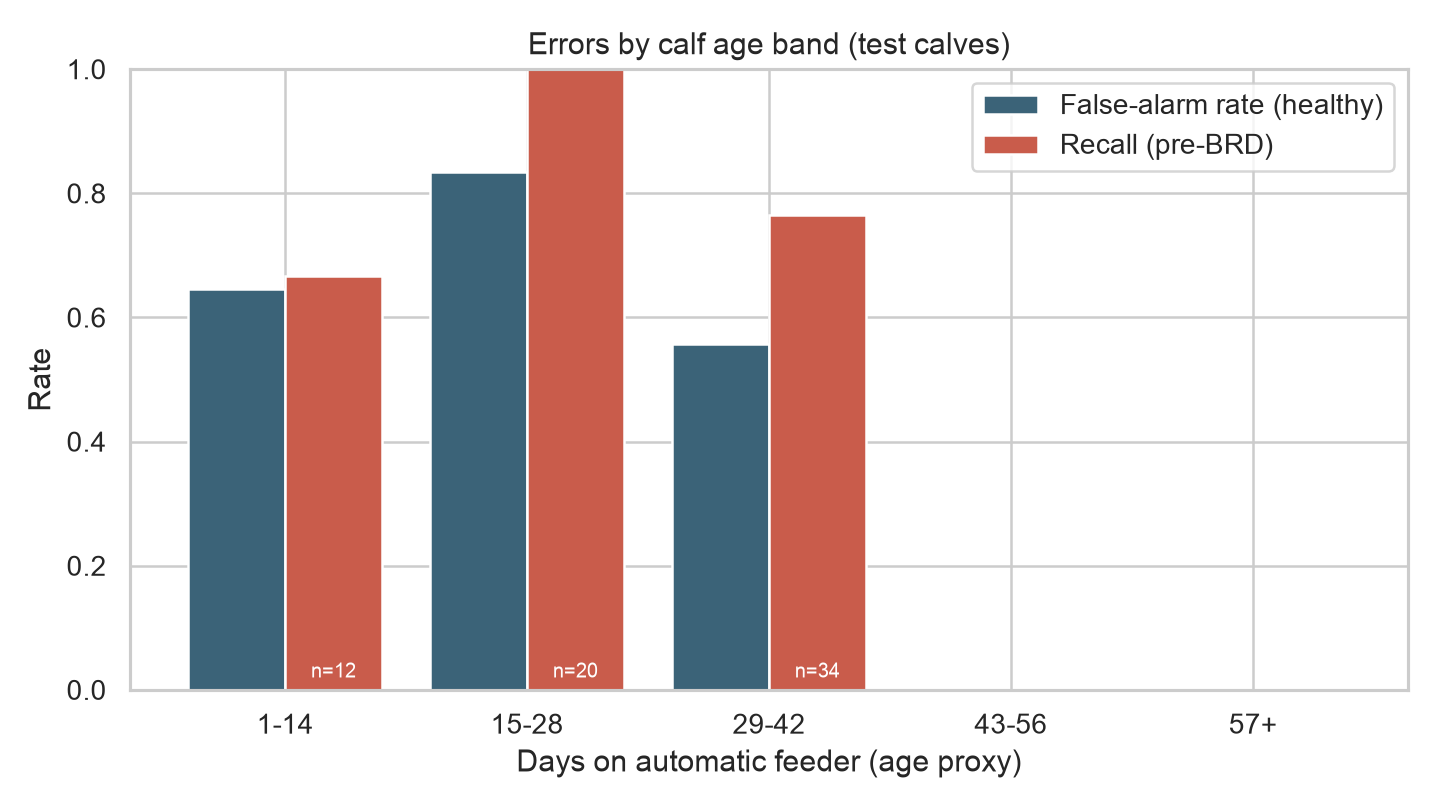

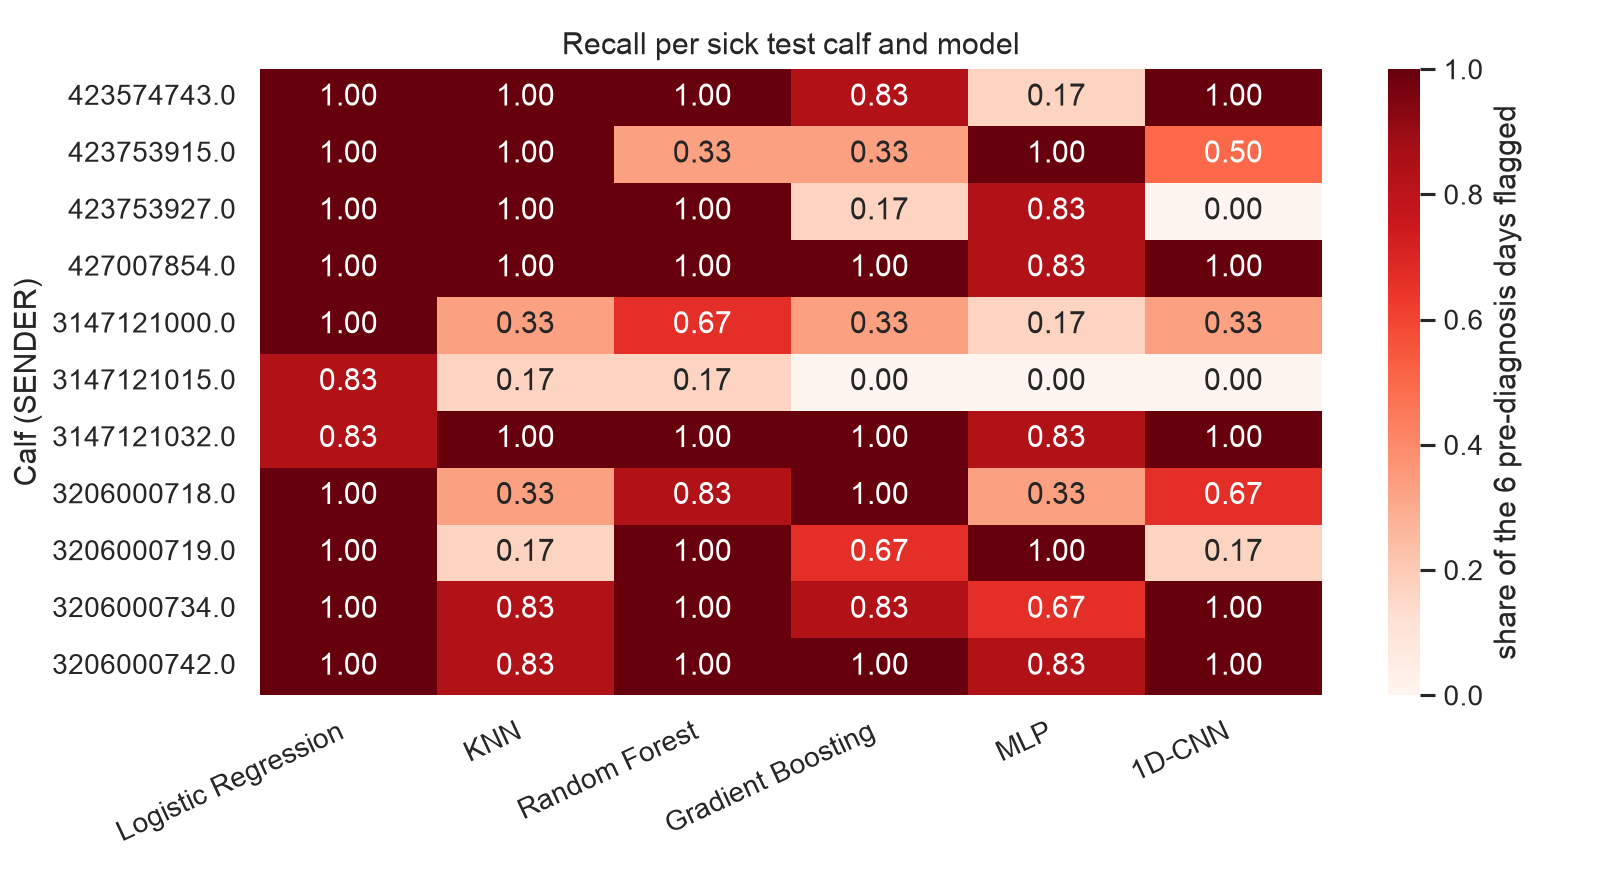

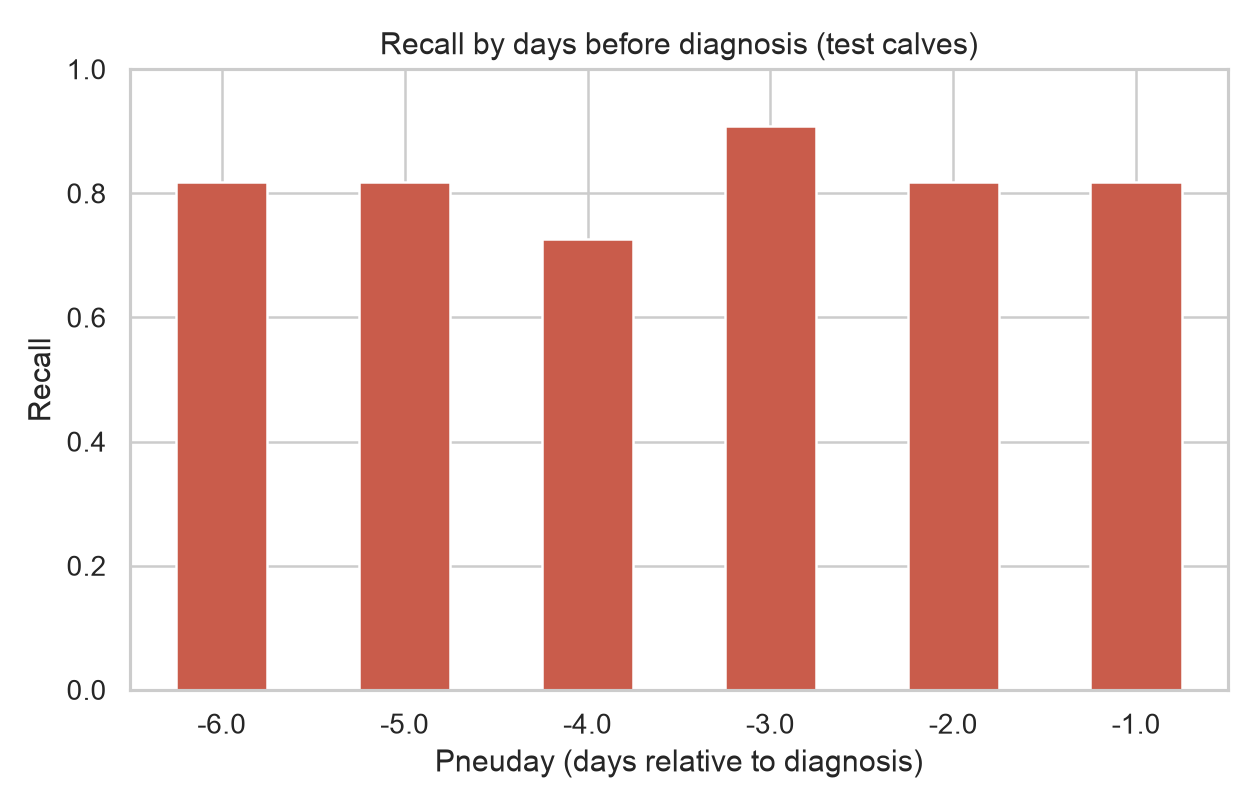

In [10]:
s=json.load(open(R+'run_summary.json'))['failure_analysis']
print({k: s[k] for k in ['confusion','sick_calves_never_flagged','healthy_calves_with_false_alarm','age_matched_auc']})
display(pd.read_csv(R+'failure_by_age.csv').round(3))
for f in ['failure_probability_overlap.png','failure_feature_profiles.png','failure_by_age.png','failure_model_agreement.png','recall_by_day.png']: display(Image(F+f, width=750))

## 10. Limitations and conclusion
The model partly learns calf age (all BRD cases occur in the first six weeks on the feeder), most false alarms come from young healthy calves, and calves without fever are often missed. The test set has only 22 calves, so metrics have wide uncertainty. This is an academic research prototype, not a veterinary diagnostic tool.